<a href="https://colab.research.google.com/github/mathiashartmann20-dot/Inspirit-AI-Investing-Detecting-Meme-Stock-Surges-from-Social-Media/blob/main/Mathias_de_Student_Neural_Networks_CV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<font color="red"><h1><b><u>MAKE A COPY OF THIS NOTEBOOK SO YOUR EDITS ARE SAVED</u></b></h1></font>

> 📋 Click **Copy to Drive** in the toolbar (or **File → Save a copy in Drive**), then work from your copy.

In [ ]:
#@title {"display-mode":"form", "form-width":"25%"}

#@markdown ## **BEFORE RUNNING ANY CODE, please change your Hardware Accelerator to GPU to run code much faster!**
#@markdown 1. Click on the **Runtime** menu at the top of the screen.
#@markdown 2. Click **Change Runtime Type**.
#@markdown 3. Choose **T4 GPU** under **Hardware Accelerator**.
#@markdown 4. Run this code cell to check you're correctly connected!

#@markdown
#@markdown <details>
#@markdown <summary><b>If you're running into GPU limits</b> when you try to switch, click here for some suggestions:</summary>
#@markdown
#@markdown <ul>
#@markdown   <li>Wait 12–24 hours for the limits to reset.</li>
#@markdown   <li>
#@markdown     Share your copy of the notebook with another Google account that hasn't met the limit, and work through the notebook with that account.
#@markdown     <ul>
#@markdown       <li>
#@markdown         You can share by clicking the "Share" button on the top right, adding the other Google email, and making them an editor.
#@markdown       </li>
#@markdown     </ul>
#@markdown   </li>
#@markdown   <li>
#@markdown     If you're using Colab GPUs extensively and want to avoid the limits completely, consider a paid subscription or purchasing compute units.
#@markdown   </li>
#@markdown </ul>
#@markdown
#@markdown </details>

import tensorflow
from IPython.display import Markdown, display

if tensorflow.test.gpu_device_name():
  display(Markdown("### ✅ GPU connected!"))
else:
  display(Markdown("### ❌ No GPU found!"))

### ✅ GPU connected!

<h1>🐶<b><i> Neural Networks: Classifying Images for a Self-Driving Car</i></b></h1>

---
---
<img src="https://futurism.com/wp-content/uploads/2023/06/self-driving-car-runs-over-dog2.jpg?quality=85" width="800">


# **🔎 Introduction**

We work for CC: ConscientiousCars, where we help self-driving vehicles be more conscientious of their surroundings. Our cars have been very good at recognizing and avoiding humans. They haven't, however, been capable of recognizing dogs. Since dogs are man's best friend and will always be where we humans are, we want our cars to know if a dog is on the road in front of them and avoid the dog!

The first step to avoiding these cute puppies is **knowing if a puppy is in front of the car**. So today we will **build a detector that can tell the difference between a dog and a road in front of it**!



> **Previously:** In Sessions 1–2, you learned Python, explored data, built a decision tree classifier, and audited it for bias. Today you'll go deeper — training a neural network to recognize images and deploying your first AI app.

## 🗺 Notebook Roadmap

Here's what you'll build today! Each milestone builds on the last:

| Milestone | What you'll do | Why it matters |
|---|---|---|
| 📊 **1. Data Exploration** | Look at the images and understand the dataset | You can't build a good model without understanding your data |
| 🧠 **2. Neural Networks** | Train your first neural network | See how a simple NN learns to classify images |
| 🖼 **3. Convolutional Neural Networks** | Train a CNN — the same architecture used in real computer vision | CNNs are purpose-built for images and significantly more accurate |
| 🔍 **4. Saliency Maps** | Peek inside the model to see *what* it's looking at | Helps us trust (or question) the model's decisions |
| 🧪 **5. Stress Testing** | Break the model on purpose | Reveals where it would fail in the real world |
| 🚀 **(Optional) 6. Your Own CV App** | Design and deploy a CV app idea with AI | Turn what you've learned into something real |
| 🌐 **(Optional) 7. Frontier AI** | See how GPT-4o-mini handles the same images | Learn how multimodal models work and compare |

In [ ]:
#@title **🏗 Setup Cell**
#@markdown **Run this to import libraries and download data!**

from collections import Counter
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Inspirit's util file and discussion exercise answer handler
if not os.path.exists('inspiritai_util.py'):
    import urllib.request
    urllib.request.urlretrieve(
        'https://storage.googleapis.com/inspirit-ai-data-bucket-1/Modules/inspiritai_util.py',
        'inspiritai_util.py'
    )
from inspiritai_util import handle_discussion_response


# Loading in data
def load_data():
  import urllib.request
  print('Downloading data...')
  urllib.request.urlretrieve(
      'https://storage.googleapis.com/inspirit-ai-data-bucket-1/Data/AI%20Scholars%20(2026)/Sessions%201%20-%205/Session%203%20-%20CV%20and%20Neural%20Networks/dogs_v_roads',
      'cifar_data'
  )
  print('Download complete.')

  import pickle
  data_dict = pickle.load(open( "cifar_data", "rb" ));

  data   = data_dict['data']
  labels = data_dict['labels']

  return data, labels

data, labels = load_data()

# Function for plotting images
def plot_one_image(data, labels, img_idx):
  img   = data[img_idx, :].reshape([32,32,3]).copy()
  label = labels[img_idx]

  fig, ax = plt.subplots(1,1)
  img = ax.imshow(img.astype('uint8'), extent=[-1,1,-1,1])

  x_label_list = [0, 8, 16, 24, 32]
  y_label_list = [0, 8, 16, 24, 32]

  ax.set_xticks([-1, -0.5, 0, 0.5, 1])
  ax.set_yticks([-1, -0.5, 0, 0.5, 1])

  ax.set_xticklabels(x_label_list)
  ax.set_yticklabels(y_label_list)

  ax.set_title(f'Image: {img_idx} | Label: {label}')

  display(fig)
  plt.close(fig)

# Helper for dropdown-style discussion answers with correct/incorrect feedback
def check_dropdown_answer(answer, correct, feedback_correct, feedback_incorrect):
    if not answer or str(answer).strip() in ('', '(pick one)'):
        print('⚠️ Pick an answer from the dropdown.')
    elif answer == correct:
        print(f'✅ {feedback_correct}')
    else:
        print(f'❌ {feedback_incorrect}')

Download complete.


<font color=red size="5"><b> ⬆ Click the play button before moving on! </b></font>

## Table of Contents
You can find a more detailed Table of Contents by clicking on the icon on the left sidebar that looks like this: <img src="https://drive.google.com/uc?export=view&id=1AGUz4POrRWu_6n5yI_YdO4qFRr41_PzE" width=20>

1. 📊 **Milestone 1: Data Exploration**
2. 🧠 **Milestone 2: Neural Networks**
3. 🖼 **Milestone 3: Convolutional Neural Networks**
4. 🔍 **Milestone 4: What Does the Model See? (Saliency Maps)**
5. 🧪 **Milestone 5: Stress Testing Your Model**
6. 🚀 **(Optional)** Milestone 6: Vibe Code Your Own CV App**
7. 🌐 **(Optional)** Milestone 7: Frontier AI & Multimodal Models

<!-- ⏱ Suggested time: 10–15 min depending on group pace -->
---
---
# **📊 Milestone 1: Data Exploration**

<img src="https://s3.ap-southeast-1.amazonaws.com/images.deccanchronicle.com/dc-Cover-blettn0hj8o3gok43isvb63oa4-20211001165615.Medi.jpeg" width="700">

## 1.1. Introducing the Data

Let's take a look at the dataset that can help our car's model tell the difference between roads and dogs. The dataset has been loaded in as `data` (the images) and `labels` (the classifications of each of the images). Note that we won't be working with Pandas DataFrames in this notebook since we're working with image data.

Try running the cell below and changing the number to see what changes!

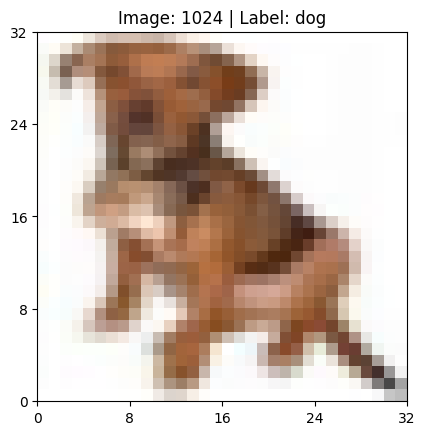

In [ ]:
# Try changing the image index — there are 1200 images total.
# Indexes 0–599 are dogs; indexes 600–1199 are roads.
plot_one_image(data, labels, 1024)

### 1.1.1. Discussion Exercise




In [ ]:
#@markdown *Why might we be using such blurry images?*
answer = "" # @param {"type":"string"}

handle_discussion_response(answer)

Next, let's try out a road image if you haven't already. Again, try changing the number:

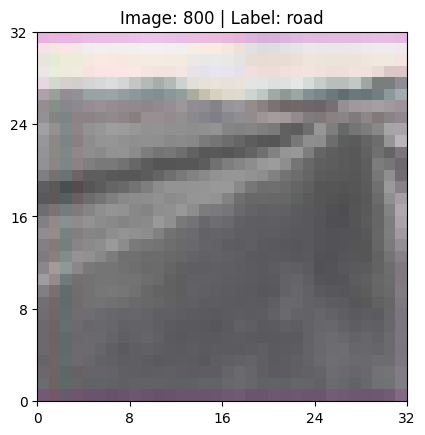

In [ ]:
plot_one_image(data, labels, 800) # Change this number

How many images do we have? Let's take a look at the length of the data using the familiar `len()` function below!

In [ ]:
# Count how many images are in our dataset
print(len(data))

1200


Let's confirm the counts:

In [ ]:
# Count how many images belong to each label (dog vs road)
print(Counter(labels))

Counter({'dog': 600, 'road': 600})


We have **600 dogs** and **600 roads** — a balanced dataset, which makes the model easier to train and evaluate fairly.

### <font color="#4a6fa5"><b>(Optional)</b> 1.1.2. Coding Exercise</font>

> Try this out if you want to use a for loop to look at more images in the dataset.

Use the code cell below to use a for loop to plot multiple images using the `plot_one_image()` function.

If you're not sure how to write for loops in Python, ask your instructor for help.

In [ ]:
### YOUR CODE HERE


### END CODE

## 1.2. Understanding our Data Representation

Let's see what the raw data looks like. The cell below will print out `data[0]` for you, which is the first image. What do you think the values mean?

> The `data[0]` notation is our way of telling Python which of the items we want from a list of items (in this case, which image we want out of the whole array of images in `data`). You can change the `0` like you did with `plot_one_image()` to see what different images may look like in numerical format!

In [ ]:
# Print the first image data
print('One image looks like:', data[0])

One image looks like: [45 20 19 ... 83 99 31]


What is each value? As a hint, let's look at how many values we have in total, using `len()`:

In [ ]:
# Each image is stored as a flat list of numbers — show how many
print("Length of list:", len(data[0]))

Length of list: 3072


Now, interpret these values below. (Hint: Check the images plotted above, and remember color 🎨.)

### 1.2.1. Discussion Question

In [ ]:
#@markdown *Using the images we plotted earlier and what you've learned about how color images are stored, fill in the blanks below!*

image_height_in_pixels = 32 #@param {type:"integer"}
image_width_in_pixels = 32 #@param {type:"integer"}
number_of_colors_per_pixel = 3 #@param {type:"integer"}

if image_height_in_pixels == 32 and image_width_in_pixels == 32 and number_of_colors_per_pixel == 3:
  print("Correct!")
  print(f"Each image is {image_height_in_pixels}x{image_width_in_pixels} pixels.")
  print(f"Each pixel has {number_of_colors_per_pixel} channels (for Red, Green, and Blue)")
else:
  print("Those aren't quite the values.")
  print(f"Your values give a total of {image_height_in_pixels * image_width_in_pixels * number_of_colors_per_pixel} intensity values per image.")
  print("Discuss with your group and try again!")


#@markdown *Once you're happy with your answers, run the cell to check if they're correct!*

Correct!
Each image is 32x32 pixels.
Each pixel has 3 channels (for Red, Green, and Blue)


In [ ]:
#@markdown *What do each of the numbers represent in the lists we saw above?*
pixel_values_meaning = "Each number is one color value (R, G, or B) of one pixel" #@param ["(pick one)", "Each number is one whole image", "Each number is the brightness of one whole pixel", "Each number is one color value (R, G, or B) of one pixel", "Each number is the model's prediction"]

check_dropdown_answer(
    pixel_values_meaning,
    correct="Each number is one color value (R, G, or B) of one pixel",
    feedback_correct="Right — every pixel needs three numbers (red, green, blue), so 32 × 32 × 3 = 3,072 numbers per image.",
    feedback_incorrect="Look back at the dimensions you filled in: 32 × 32 × 3 = 3,072. What do all those numbers add up to describe?"
)

✅ Right — every pixel needs three numbers (red, green, blue), so 32 × 32 × 3 = 3,072 numbers per image.


The whole dataset is just lists of these values, for each image (i.e. 1200 × 3072 values):

In [ ]:
# Show the full shape and values of our dataset
print('Data shape:', data.shape)
print('Data:\n', data)

Data shape: (1200, 3072)
Data:
 [[ 45  20  19 ...  83  99  31]
 [101 114  35 ... 155 134  91]
 [213 221 221 ... 139  58  47]
 ...
 [126 174 202 ... 124 128 129]
 [191 232 240 ...  74  93  81]
 [237 248 254 ...  45  56  10]]


Now that we understand our data, let's prepare it for machine learning. Run the code in the cell below to split the data into training and testing sets, so make can learn patterns and make predictions!

In [ ]:
# Split data into 80% training and 20% testing
# random_state=1 means we get the same split every time (reproducible)
X_train, X_test, y_train, y_test = train_test_split(data, labels, test_size=0.2, random_state=1)

✅ **Milestone 1 done!** You've explored the dataset, seen what the images look like, and understood how they're represented as numbers. Now you'll build your first model.

<!-- ⏱ Suggested time: 15–20 min depending on group pace -->
---
---
# **🧠 Milestone 2: Neural Networks**

<img src="https://media.geeksforgeeks.org/wp-content/cdn-uploads/20230602113310/Neural-Networks-Architecture.png" width="700">

Now, let's create some new models using neural networks!

<details>
<summary><b>(Optional) 💡 Want more intuition first? — click to expand</b></summary>

Try [TensorFlow Playground](https://playground.tensorflow.org/) — an interactive demo where you can build and train tiny neural networks in your browser to get a feel for how they learn.

</details>

## 2.1. Building a Neural Network using Scikit-Learn

To build a simple neural network, we use `MLPClassifier` from scikit-learn. We will play with the **number of neurons** and the **number of hidden layers** to adjust the complexity of our model, just like we did in Playground!

**Example 1:**
Here's how we create a neural network with 1 hidden layer of 3 neurons.

```python
nnet_model = MLPClassifier(hidden_layer_sizes=(3))
```

**Example 2:**

Here's how we create a neural network with 2 hidden layers: one of 3 neurons and one of 4 neurons.

```python
nnet_model = MLPClassifier(hidden_layer_sizes=(3, 4))
```


### 2.1.1. Coding Exercise
How might you build a neural network with more hidden layers? Fill out the code below to train and test your model!

We've provided the first line for you, but you should change around the `hidden_layer_sizes` parameter to improve your results.

In [ ]:
# 1. Initialize neural network model
nnet_model = MLPClassifier(hidden_layer_sizes=(3, 3, 1), random_state=1, max_iter=1000000) # Change `hidden_layer_sizes` (Hint: Check examples above)

# 2. Train the model on the training images/labels
# 💡 Hint: use the .fit() method on nnet_model, passing in the training data and training labels.
nnet_model.fit(X_train, y_train)

# 3. Get the model's predictions on the testing data
# 💡 Hint: use the .predict() method on nnet_model with the testing data. Save the result as y_pred.
y_pred = nnet_model.predict(X_test)
# 4. Print the accuracy score on the testing data
# 💡 Hint: use accuracy_score(__ , __) — it takes the true labels and your predicted labels.

print('Accuracy:', accuracy_score(y_test, y_pred) * 100, '%')

Accuracy: 52.916666666666664 %


As you continue to tweak your neural network, use the next two code cells to dive deeper! What kinds of mistakes is your model making? Can you find specific examples of pictures where it's getting it wrong?

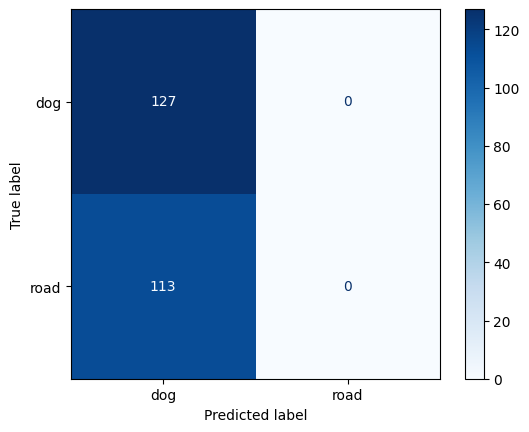

In [ ]:
#@markdown ### Run this to display the confusion matrix for your model!
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

cnf_matrix = confusion_matrix(y_test, y_pred, labels=['dog', 'road'])
disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matrix,
                              display_labels=['dog', 'road'])
disp.plot(cmap='Blues')

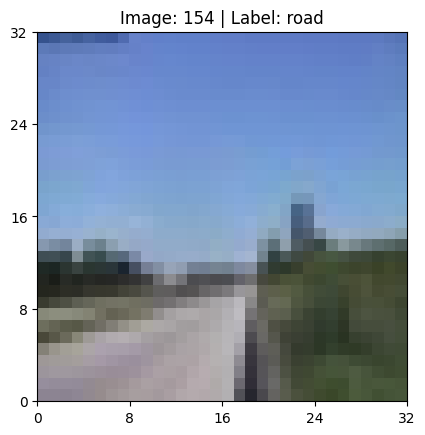

prediction: dog


In [ ]:
#@title {'run' : 'auto'}
#@markdown ### Choose an image index to display the image and your model's prediction!

# Specify which image you want to show
image_id = 154 # @param {"type":"slider","min":0,"max":240,"step":1}

# Visualize the image
plot_one_image(X_test, y_test, image_id)

# Use the model to predict what this might be and print it
print('prediction:', y_pred[image_id])

**How well did your neural network perform?**

Multilayer perceptrons are more complex models and it can be difficult to find the right "settings" for them. It takes some trial and error!

✅ **Milestone 2 done!** You trained a neural network and saw how accuracy changes with different architectures. CNNs are a more powerful approach — purpose-built for images. Let's see how much better they do.

### <font color="#4a6fa5"><b>(Optional)</b> 2.1.2. Coding Exercise</font>

> Try this out if you'd like to use a for loop to automate testing out different layer architectures!

Use a for loop to automate your investigation. Explore different numbers of hidden layers, the size of the hidden layers, and the number of iterations! How well can you get your network performing?

If you're not sure how to write for loops in Python, ask your instructor for help. (Hint: create a list of hidden layers to test!)

In [ ]:
### YOUR CODE HERE

### <font color="#4a6fa5"><b>(Optional)</b> 2.1.3. Coding Exercise</font>

> Try this out if you'd like to use code to find the specific examples of where your model is making errors.

Our classifications are OK, but are they good enough for our conscientious cars? Let's put on our detective hats to determine the root causes of the incorrect classifications!

Below, please print out 4 images of true positives, 4 images of true negatives, 4 images of false positives, and 4 images of false negatives. We've provided the code for printing 4 true positives below.

What are the reasons for failure (both for false positives and false negatives)?

In [ ]:
# True Positives (code provided)

# Show up to 4 true positives: model correctly predicted 'dog'
print("TRUE POSITIVES")
tp_count = 0
i = 0
# stop after 4 examples or end of test set
while tp_count < 4 and i < len(X_test):
    # prediction matches and is 'dog'
    if y_pred[i] == y_test[i] and y_pred[i] == 'dog':
        plot_one_image(X_test, y_test, i)
        print("  Predicted:", y_pred[i], "| True:", y_test[i])
        # found one, increment counter
        tp_count += 1
    # move to next image
    i += 1

# False Positives
### WRITE YOUR CODE BELOW

# True Negatives
### WRITE YOUR CODE BELOW

# False Negatives
### WRITE YOUR CODE BELOW

<!-- ⏱ Suggested time: 10–15 min depending on group pace -->
---
---
# **🖼 Milestone 3: Convolutional Neural Networks**


<img src="https://www.researchgate.net/publication/339008531/figure/fig1/AS:941759408402435@1601544348744/A-simple-convolutional-neural-network-CNN-and-its-main-layers.png" width="700">

> There is a famous type of neural network known as convolutional neural networks (CNNs), which work particularly well on computer vision problems.  Train one in this section!

In [ ]:
#@title **🏗 Run this cell to define the `CNNClassifier`!**

import tensorflow.keras as keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D
from tensorflow.keras.layers import Activation, MaxPooling2D, Dropout, Flatten, Reshape

def logits_to_one_hot_encoding(input):
    """
    Converts softmax output (logits) to a one-hot encoded format.

    This function takes an array of softmax output probabilities
    (usually from a neural network's output layer) and converts
    each row to a one-hot encoded vector. The highest probability
    in each row is marked as 1, with all other values set to 0.

    Parameters:
    input (numpy.ndarray): A 2D array where each row contains softmax probabilities for each class.
                            The shape of the array is (n_samples, n_classes).

    Returns:
    numpy.ndarray: A 2D array of the same shape as the input, where each row is the one-hot encoded representation
                   of the class with the highest probability in the original row.
    """

    output = np.zeros_like(input, dtype=int)
    output[np.arange(len(input)), np.argmax(input, axis=1)] = 1
    return output

def plot_acc(history, ax = None, xlabel = 'Epoch #'):
    history = history.history
    history.update({'epoch':list(range(len(history['val_accuracy'])))})
    history = pd.DataFrame.from_dict(history)

    best_epoch = history.sort_values(by = 'val_accuracy', ascending = False).iloc[0]['epoch']

    if not ax:
      f, ax = plt.subplots(1,1)
    sns.lineplot(x = 'epoch', y = 'val_accuracy', data = history, label = 'Validation', ax = ax)
    sns.lineplot(x = 'epoch', y = 'accuracy', data = history, label = 'Training', ax = ax)
    ax.axhline(0.5, linestyle = '--',color='red', label = 'Chance')
    ax.axvline(x = best_epoch, linestyle = '--', color = 'green', label = 'Best Epoch')
    ax.legend(loc = 7)
    ax.set_ylim([0.4, 1])

    ax.set_xlabel(xlabel)
    ax.set_ylabel('Accuracy (Fraction)')

    plt.show()

def categorical_to_onehot(labels_in):
  labels = []
  for label in labels_in:
    if label == 'dog':
      labels.append(np.array([1, 0]))
    else:
      labels.append(np.array([0, 1]))
  return np.array(labels)

class CNNClassifier:
    """
    A Convolutional Neural Network (CNN) classifier using Keras, customized for binary classification tasks.

    This class wraps a Keras Sequential model with a specific architecture suitable for image classification tasks.
    It includes a custom `predict` method that outputs one-hot encoded predictions, and other standard Keras model
    methods are accessible as well. This was done to override the need for the SciKeras wrappers that is frequently
    incompatible with Google Colab versions of Keras & Tensorflow. Feel free to modify as needed.

    Attributes:
        num_epochs (int): The number of training epochs.
        layers (int): The number of convolutional layers in the model.
        dropout (float): The dropout rate used in dropout layers for regularization.
        model (keras.models.Sequential): The underlying Keras Sequential model.

    Methods:
        build_model(): Constructs the CNN model with the specified architecture and compiles it.

        fit(*args, **kwargs): Trains the model. Accepts arguments compatible with the Keras `fit` method.

        predict(*args, **kwargs): Predicts labels for the input data. Converts the softmax output of the model
                                  to one-hot encoded format using `logits_to_one_hot_encoding`. Necessary to match
                                  accuracy_score function expected arguments.

        predict_proba(*args, **kwargs): Predicts labels for the input data and returns the raw output of the softmax.
                                        Used when wanting to inspect the raw probabilistic scoring of the model.

    Usage:
        cnn_classifier = CNNClassifier(num_epochs=30, layers=4, dropout=0.5)
        cnn_classifier.fit(X_train, y_train)
        predictions = cnn_classifier.predict(X_test)

    Note:
        The `__getattr__` method is overridden to delegate attribute access to the underlying Keras model,
        except for the `predict` method which is customized.
    """
    def __init__(self, num_epochs=30, layers=4, dropout=0.5):
        self.num_epochs = num_epochs
        self.layers = layers
        self.dropout = dropout
        self.model = self.build_model()

    def build_model(self):
        model = Sequential()
        model.add(Reshape((32, 32, 3)))

        for i in range(self.layers):
          model.add(Conv2D(32, (3, 3), padding='same'))
          model.add(Activation('relu'))

        model.add(Conv2D(32, (3, 3)))
        model.add(Activation('relu'))
        model.add(MaxPooling2D(pool_size=(2, 2)))
        model.add(Dropout(self.dropout))

        model.add(Conv2D(64, (3, 3), padding='same'))
        model.add(Activation('relu'))
        model.add(Conv2D(64, (3, 3)))
        model.add(Activation('relu'))
        model.add(MaxPooling2D(pool_size=(2, 2)))
        model.add(Dropout(self.dropout))

        model.add(Flatten())
        model.add(Dense(512))
        model.add(Activation('relu'))
        model.add(Dropout(self.dropout))
        model.add(Dense(2))
        model.add(Activation('softmax'))
        opt = keras.optimizers.RMSprop(learning_rate=0.0001)
        model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])

        return model

    def fit(self, *args, **kwargs):
        return self.model.fit(*args, epochs=self.num_epochs, batch_size=10, verbose=2, **kwargs)

    #NOTE: WRITTEN TO RETURN ONE HOT ENCODINGS FOR ACCURACY
    def predict(self, *args, **kwargs):
        predictions = self.model.predict(*args, **kwargs)
        return logits_to_one_hot_encoding(predictions)

    def predict_proba(self, *args, **kwargs):
        predictions = self.model.predict(*args, **kwargs)
        return predictions

    def score(self, X, y):
        predictions = self.predict(X)
        return accuracy_score(y, predictions)

    def __getattr__(self, name):
        if name != 'predict' and name != 'predict_proba':
            return getattr(self.model, name)
        else:
            raise AttributeError(f"'{self.__class__.__name__}' object has no attribute '{name}'")


> 💡 **Heads-up:** `CNNClassifier` is a custom class built by Inspirit AI for this notebook — it's not part of any standard library. You can treat it similarly to previous models (like using `fit()` and `predict()` on it). Training may take a few minutes if you're not connected to GPU!

## 3.1. Using the `CNNClassifier`

Before training the CNN, we need to tweak the data into the format it expects. The CNN needs two small format changes:

- **Pixel values as decimals** (e.g. `0.0` to `255.0`) instead of whole numbers
- **Labels in one-hot form** — a list of `0`s with a `1` marking the correct class. So `'dog'` becomes `[1, 0]` and `'road'` becomes `[0, 1]`.

**Run the cell below** — it does the conversion for you.

In [ ]:
# Convert pixel values from whole numbers to decimals
X_train = X_train.astype(float)
X_test = X_test.astype(float)

# Convert labels into one-hot form (e.g. 'dog' → [1, 0], 'road' → [0, 1])
y_train_onehot = categorical_to_onehot(y_train)
y_test_onehot = categorical_to_onehot(y_test)

# Verify one-hot labels
print(y_train[1], "->", y_train_onehot[1]) # road image
print(y_train[2], "->", y_train_onehot[2]) # dog image


road -> [0 1]
dog -> [1 0]


### 3.1.1. Coding Exercise

For initiating a basic CNN, execute the following command:

```python
cnn = CNNClassifier(num_epochs=N)
```

Here, `num_epochs` denotes the number of times the neural network will go through the entire training dataset while training.

In the code cell below, create, train, and test the `CNNClassifier`. We'll also save the **training history** during training so we can plot the learning curves in the next section — that means passing `validation_data` to `.fit()` and capturing the result as `history`.

> **Note:** Use the new `X_train`, `X_test`, `y_train_onehot`, and `y_test_onehot` from the previous section.

In [ ]:
# 1. Initialize the CNN
# 💡 Hint: see the example above — CNNClassifier(num_epochs=...). Pick a value for N (e.g. 20).

cnn = CNNClassifier(num_epochs= 8)

# 2. Train the CNN, and save the training history so we can plot learning curves later
# 💡 Fill in: which data should the CNN train on? Which data should it validate against?
history = cnn.fit(X_train, y_train_onehot, validation_data=(X_test, y_test_onehot))   # TO-DO: fill in training data, training labels, test data, test labels


# 3. Predict what the classes are based on the testing data
# 💡 Hint: use the .predict() method on your cnn with the testing data. Save the result as predictions.
predictions = cnn.predict(X_test)

# 4. Print the accuracy score on the testing data
# 💡 Hint: use accuracy_score(...) — it takes the true one-hot labels (y_test_onehot) and your predictions.
print('CNN test score accuracy:',accuracy_score(y_test_onehot, predictions) * 100, '%')



# ## 1. Initialize neural network model
# nnet_model = MLPClassifier(hidden_layer_sizes=(3, 3, 1), random_state=1, max_iter=1000000) # Change `hidden_layer_sizes` (Hint: Check examples above)

# # 2. Train the model on the training images/labels
# # 💡 Hint: use the .fit() method on nnet_model, passing in the training data and training labels.
# nnet_model.fit(X_train, y_train)

# # 3. Get the model's predictions on the testing data
# # 💡 Hint: use the .predict() method on nnet_model with the testing data. Save the result as y_pred.
# y_pred = nnet_model.predict(X_test)
# # 4. Print the accuracy score on the testing data
# # 💡 Hint: use accuracy_score(__ , __) — it takes the true labels and your predicted labels.

# print('Accuracy:', accuracy_score(y_test, y_pred) * 100, '%')

Epoch 1/8
96/96 - 11s - 110ms/step - accuracy: 0.6375 - loss: 1.8372 - val_accuracy: 0.8875 - val_loss: 0.3145
Epoch 2/8
96/96 - 1s - 6ms/step - accuracy: 0.8062 - loss: 0.5175 - val_accuracy: 0.8708 - val_loss: 0.3183
Epoch 3/8
96/96 - 0s - 5ms/step - accuracy: 0.8521 - loss: 0.3519 - val_accuracy: 0.9083 - val_loss: 0.2700
Epoch 4/8
96/96 - 0s - 5ms/step - accuracy: 0.8802 - loss: 0.2910 - val_accuracy: 0.9167 - val_loss: 0.2291
Epoch 5/8
96/96 - 1s - 6ms/step - accuracy: 0.9042 - loss: 0.2775 - val_accuracy: 0.9583 - val_loss: 0.1538
Epoch 6/8
96/96 - 0s - 5ms/step - accuracy: 0.9229 - loss: 0.2326 - val_accuracy: 0.9167 - val_loss: 0.2050
Epoch 7/8
96/96 - 0s - 5ms/step - accuracy: 0.9250 - loss: 0.2059 - val_accuracy: 0.9333 - val_loss: 0.1621
Epoch 8/8
96/96 - 0s - 5ms/step - accuracy: 0.9115 - loss: 0.2344 - val_accuracy: 0.9667 - val_loss: 0.1541
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step
CNN test score accuracy: 96.66666666666667 %


### 3.1.2. Discussion Exercise

In [ ]:
#@markdown *1. What was your best accuracy? Is this good enough?*
answer_1 = "96.666666666666666667%" # @param {"type":"string"}

#@markdown *2. You and your classmates may have a different max accuracy. Why might that be?*
answer_2 = "their num_epochs" # @param {"type":"string"}

handle_discussion_response(answer_1, answer_2)

Your answers:

------------------------------1------------------------------
96.666666666666666667%
-------------------------------------------------------------

------------------------------2------------------------------
their num_epochs
-------------------------------------------------------------

If you haven't already, discuss with your classmates!


## 3.2. Training and Validation Curves

An important aspect of training neural networks is to prevent overfitting. **How do you know when your model is overfitting?**

When you trained the CNN above, we saved the training history into a variable called `history`. Use the `plot_acc()` helper to visualize how the training and validation accuracy changed across epochs:

```python
plot_acc(history)
```

### 3.2.1. Coding Exercise

Use `plot_acc(history)` to visualize the learning curves.

Then look at the plot and answer:
- **Where does training accuracy land vs. validation accuracy?**
- **Is the model overfitting?** Overfitting shows up as training accuracy climbing while validation accuracy plateaus or drops. If you don't see that pattern clearly, that's a valid reading too — the model may not be overfitting much in this run.
- **At which epoch did validation accuracy peak?** That's roughly the "best" version of this model.

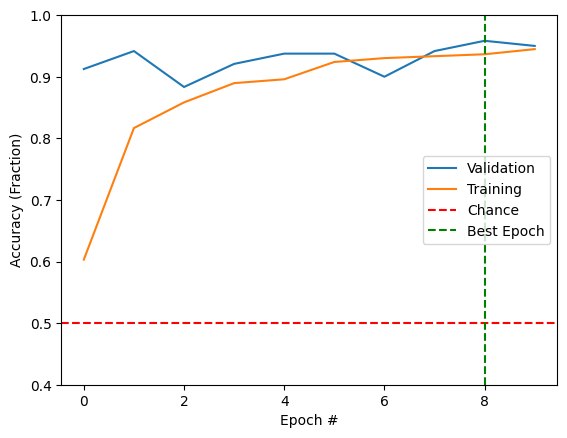

In [ ]:
### YOUR CODE HERE
# 💡 Hint: pass the `history` variable from the previous section into plot_acc().
plot_acc(history)



✅ **Milestone 3 done!** Your CNN should be hitting 80–90% accuracy — a real improvement. But *why* is it making the decisions it makes? Saliency maps let us look inside.

<!-- ⏱ Suggested time: 15–20 min depending on group pace (includes training time) -->
---
---
# **🔍 Milestone 4: What Does the Model See? (Saliency Maps)**

> Neural networks are powerful, but they're also a "black box." In this section, you'll peek inside and see what your CNN actually focuses on when making decisions!

> ⏱ *Heads-up: computing saliency maps can take ~1–3 minutes per image if not connected to GPU.*

<img src="https://miro.medium.com/1*SG0BpRw562AIBWU-xpem0g.png" width="700">

Neural networks have achieved incredible results in many fields. But they have a big problem: it's very difficult to explain exactly why a neural network makes the decisions it does. This makes it difficult to trust them in high-stakes applications like medicine, self-driving cars, and criminal justice — would you trust an AI that diagnosed you with a disease, but couldn't explain why?

Researchers are currently studying ways to make neural networks more explainable. One approach is using **saliency maps** to figure out the saliency (importance) of each individual pixel. Intuitively, we're trying to understand the neural network by tracking what it "pays attention" to.

## 4.1. Choosing an Image to Investigate

Let's pick an image from our test set and see how the CNN classifies it. Then, we'll create its saliency map to see which parts of the image the model focused on most.

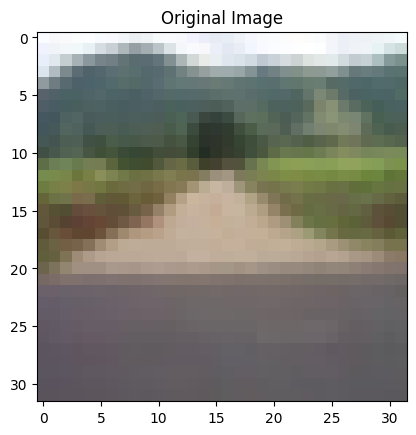

Image index: 84
True label: road
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
CNN prediction: road


In [ ]:
#@title 4.1. Pick an image { run: "auto" }
image_index = 84 #@param {type:"slider", min:0, max:100, step:1}

# Get input image
input_image = X_test[image_index]
# Get image label
true_label = y_test[image_index]

# Plot image
plt.imshow(input_image.reshape(32,32,3).astype(int))
plt.title("Original Image")
plt.show()

print(f"Image index: {image_index}")
print(f"True label: {true_label}")

prediction_onehot = cnn.predict(np.array([input_image]))[0]
prediction_label = "dog" if prediction_onehot[0] == 1 else "road"
print(f"CNN prediction: {prediction_label}")

## 4.2. Building a Saliency Map

Saliency maps show which specific pixels matter most to a model's prediction.

The core idea: **if changing a pixel changes the prediction a lot, that pixel must be important.** If changing it doesn't matter, it's unimportant.

In math terms, a pixel's saliency is:

$$D = \left|\frac{\Delta \text{probability}}{\Delta \text{pixel}}\right|$$

- $\Delta \text{pixel}$ = the small change we make to a pixel’s value  
- $\Delta \text{probability}$ = how much the model’s prediction changes  

So, if a small pixel change causes a big prediction change, that pixel is important!

First, let's get the original predicted probabilities:

In [ ]:
# Get the model's original predicted probabilities for the chosen image
pred = cnn.predict_proba(np.array([input_image]))  # shape: (1, 2)
print("Prediction output:", pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Prediction output: [[0.00276404 0.9972359 ]]


`pred` contains two numbers. What does each one represents?

First, let's get the original predicted probabilities for the chosen image above:

In [ ]:
# Get the probabilities for each class
dog_prob = pred[0][0]
road_prob = pred[0][1]

print(f"Probability of dog:  {dog_prob:.3f}")
print(f"Probability of road: {road_prob:.3f}")

Probability of dog:  0.003
Probability of road: 0.997


Now that we have our baseline `dog_prob`, we're going to compute a **saliency score** for every pixel in the image.

The idea is simple:  
- Change one pixel slightly → get a new prediction → measure how much it changes.  
  - Big change → **important pixel**  
  - Small change → **less important pixel**  

We repeat this for all **3,072 pixels** to create a **heatmap** showing what the model focused on.

<details>
<summary><b><font color="#4a6fa5">(Optional) Understanding the Logic — click to expand the step-by-step version</font></b></summary>

For each pixel, we slightly change its value, re-run the model, and record how much the prediction shifted. That shift is the pixel's saliency score — the bigger the shift, the more important that pixel is.

This code shows the simple, slower way to achieve this:

> **We won't run this cell** — with 3,072 pixels and 6 nudges each, it would take ~10 minutes. Read it, then run the fast version in the next cell.

```python
# Step 1: Get the model’s prediction on the original (unchanged) image.
# This gives us a baseline probability to compare against.
original_probs = cnn.predict_proba(np.array([input_image]))
dog_prob = original_probs[0][0]  # Probability that the model predicts "dog" (0 to 1)

# This list will store a saliency score for each pixel
saliencies = []

# Step 2: Loop over every pixel in the image
# (For a 32x32 RGB image, that's 32 * 32 * 3 = 3,072 pixels)
for pixel_index, pixel_value in enumerate(input_image):

    # For this pixel, we’ll measure how sensitive the model is
    # by slightly increasing/decreasing its value
    D_values = []

    # Step 3: Try multiple small changes ("nudges") to this pixel
    for nudge in [-50, -30, -10, 10, 30, 50]:
        
        # Apply the nudge
        new_pixel_value = pixel_value + nudge

        # Skip invalid pixel values (must stay within 0–255)
        if not (0 <= new_pixel_value <= 255):
            continue

        # Step 4: Create a temporary modified image
        # (We copy so the original image stays unchanged)
        modified_image = input_image.copy()

        # Change only this one pixel
        modified_image[pixel_index] = new_pixel_value

        # Step 5: Get the model’s new prediction for the modified image
        modified_probs = cnn.predict_proba(np.array([modified_image]))
        new_dog_prob = modified_probs[0][0]

        # Step 6: Measure sensitivity (D)
        # How much did the prediction change per unit of pixel change?
        # Larger values = this pixel has more influence on the prediction
        D = abs((new_dog_prob - dog_prob) / nudge)
        D_values.append(D)

    # Step 7: Aggregate sensitivity for this pixel
    # We take the average across all valid nudges
    saliency = np.mean(D_values)
    saliencies.append(saliency)

# Final output: one saliency score per pixel
print("Done! Saliency scores computed for every pixel.")
print(f"Range: {min(saliencies):.4f} – {max(saliencies):.4f}")
```
</details>

### 4.2.1. Compute the Saliency Map

This cell runs the calculation we just described — nudging each of the 3,072 pixels in turn and measuring how much the model's prediction shifts. It uses batched math under the hood, so it finishes in ~1–2 minutes instead of ~10.

> ⏱ *Run it now and discuss with your group while it runs: which parts of the image do you expect the model to focus on?*

In [ ]:
#@title Run cell to compute the saliency map  {"display-mode":"form", "form-width":"25%"}

# Step 1: Define the pixel changes (nudges) we will test
NUDGES = np.array([-50, -30, -10, 10, 30, 50])

# Step 2: Get basic sizes
num_pixels = input_image.size
num_nudges = len(NUDGES)

# Step 3: Preallocate memory for efficiency
# We reserve space for the maximum possible number of modified images
max_changes = num_pixels * num_nudges

modified_images = np.empty((max_changes, num_pixels), dtype=input_image.dtype)
nudge_amounts = np.empty(max_changes, dtype=np.float32)
changes_per_pixel = np.zeros(num_pixels, dtype=np.int32)

# Step 4: Generate all modified images
# For each pixel, apply valid nudges and store the results
idx = 0  # tracks position in modified_images

for pixel_idx in range(num_pixels):
    pixel_val = input_image[pixel_idx]

    # Try all nudges for this pixel
    for nudge in NUDGES:
        new_val = pixel_val + nudge

        # Skip invalid pixel values (must stay between 0 and 255)
        if 0 <= new_val <= 255:

            # Create a modified image with one pixel changed
            modified = input_image.copy()
            modified[pixel_idx] = new_val

            # Store results
            modified_images[idx] = modified
            nudge_amounts[idx] = nudge

            idx += 1
            changes_per_pixel[pixel_idx] += 1  # count valid nudges

# Step 5: Remove unused preallocated space
modified_images = modified_images[:idx]
nudge_amounts = nudge_amounts[:idx]

# Step 6: Get baseline prediction (original image)
original_dog_prob = cnn.predict_proba(input_image[None])[0, 0]

# Step 7: Get predictions for all modified images (batched)
modified_probs = cnn.predict_proba(modified_images)[:, 0]

# Step 8: Compute saliency scores for each pixel
# We measure how much the prediction changes when the pixel is modified
saliencies = np.zeros(num_pixels, dtype=np.float32)

batch_idx = 0  # tracks position in modified_probs

for pixel_idx in range(num_pixels):
    count = changes_per_pixel[pixel_idx]

    # If no valid nudges, assign zero saliency
    if count == 0:
        continue

    # Get predictions and nudges for this pixel
    probs = modified_probs[batch_idx : batch_idx + count]
    nudges = nudge_amounts[batch_idx : batch_idx + count]

    # Step 9: Compute sensitivity values
    # D = |change in prediction / change in pixel value|
    D_values = np.abs((probs - original_dog_prob) / nudges)

    # Step 10: Average sensitivity = saliency score
    saliencies[pixel_idx] = np.mean(D_values)

    batch_idx += count  # move to next pixel's data

# Final output: one saliency score per pixel
print("Done! Saliency scores computed for every pixel.")
print(f"Range: {min(saliencies):.2e} – {max(saliencies):.2e}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
559/559 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
Done! Saliency scores computed for every pixel.
Range: 2.44e-08 – 8.44e-06


## 4.3. Visualizing the Saliency Map

Before we visualize our saliency values, we need to **normalize** them to the 0-1 range so they show up as a visible heatmap. (Otherwise, they're too small to see.)

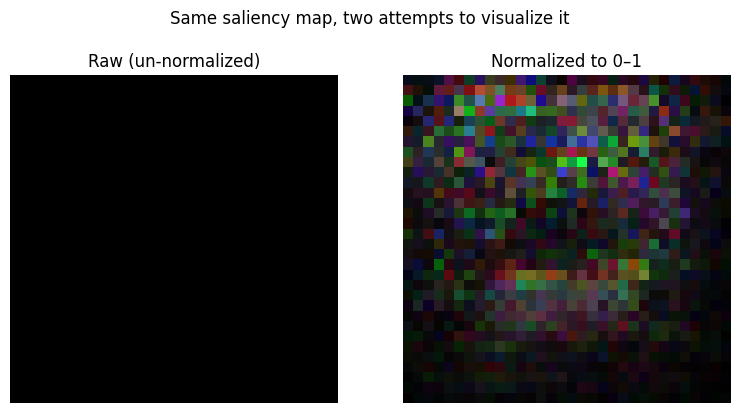

In [ ]:
#@title Run cell — and click to expand to check out the normalization code optionally { display-mode: "form" }
import numpy as np

# Convert the list of saliency values into a NumPy array for math operations
sal_array = np.array(saliencies)

# Reshape the flat array into a 32×32 grid with 3 color channels (RGB)
sal_2d_raw = sal_array.reshape(32, 32, 3)

# Normalize: subtract the global minimum so the lowest value becomes 0,
# then divide by the range (max - min) so the highest value becomes 1.
# Every value now lives in [0, 1]
sal_2d_norm = (sal_array - sal_array.min()) / (sal_array.max() - sal_array.min())

# Reshape the normalized flat array back into 32×32×3 for display
sal_2d_norm = sal_2d_norm.reshape(32, 32, 3)

# --- Visualization: side-by-side comparison ---
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# Left: raw values
axes[0].imshow(sal_2d_raw)
axes[0].set_title('Raw (un-normalized)')
axes[0].axis('off')

# Right: normalized values
axes[1].imshow(sal_2d_norm)
axes[1].set_title('Normalized to 0–1')
axes[1].axis('off')

plt.suptitle('Same saliency map, two attempts to visualize it', y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
#@markdown *Why does normalization matter for visualization?*
normalization_answer = "Without normalizing, values are too tiny to see — the heatmap is nearly black" #@param ["(pick one)", "The model gets more accurate when we normalize", "Without normalizing, values are too tiny to see — the heatmap is nearly black", "Normalizing changes which pixels are most important", "It speeds up the saliency computation"]

check_dropdown_answer(
    normalization_answer,
    correct="Without normalizing, values are too tiny to see — the heatmap is nearly black",
    feedback_correct="Right — a single pixel nudge only causes a tiny shift in the model's output, so raw saliency values are very close to zero. Scaling them to 0–1 spreads them across the full visible range.",
    feedback_incorrect="Look at the two images side by side — what changed between them, and what stayed the same?"
)

✅ Right — a single pixel nudge only causes a tiny shift in the model's output, so raw saliency values are very close to zero. Scaling them to 0–1 spreads them across the full visible range.


Great, now let's see what the model is paying attention to!

We average the three color channels into one importance score per pixel, then normalize so the range is 0–1. That score becomes brightness on the heatmap — bright means that pixel strongly influenced the prediction, dark means it had little effect.

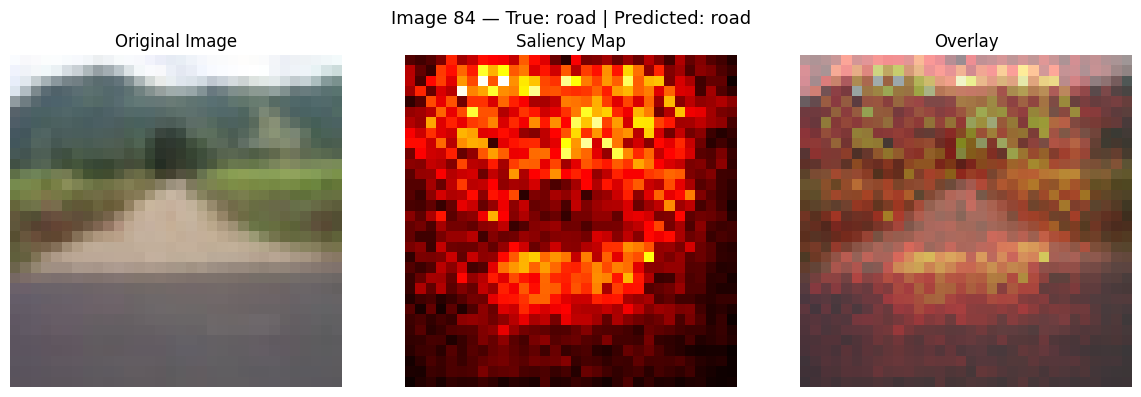

In [ ]:
#@title Plot the saliency map + original image { display-mode: "form" }


# Plot original image, saliency map, and overlay side by side
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# Left: the original image
axes[0].imshow(input_image.reshape(32,32,3).astype(int))
axes[0].set_title("Original Image")
axes[0].axis('off')

# Middle: grayscale heatmap — average across R,G,B channels so color doesn't interfere
sal_2d = sal_array.reshape(32,32,3).mean(axis=2)
axes[1].imshow(sal_2d, cmap='hot')
axes[1].set_title("Saliency Map")
axes[1].axis('off')

# Right: saliency heatmap overlaid on the original image
axes[2].imshow(input_image.reshape(32,32,3).astype(int))
axes[2].imshow(sal_2d, cmap='hot', alpha=0.4)
axes[2].set_title("Overlay")
axes[2].axis('off')

# Title shows which image we're looking at and whether the model got it right
plt.suptitle(f"Image {image_index} — True: {true_label} | Predicted: {prediction_label}", fontsize=13)
plt.tight_layout()
plt.show()

### 4.3.1. Discussion Exercise

In [ ]:
#@markdown *1. What parts of the image does the model focus on? Does this make sense?*
answer_1 = "Trees in the distant and the road closer to him" # @param {"type":"string"}

#@markdown *2. Are there any surprising areas the model pays attention to?*
answer_2 = "" # @param {"type":"string"}

handle_discussion_response(answer_1, answer_2)

> <font color="#4a6fa5"><b>(Optional)</b></font> Want to try another image? Re-run from Section 4.1 with a different image index to see what the model focuses on for that one.

✅ **Milestone 4 done!** You've seen which pixels your model focuses on. Now let's find out how fragile it is — what happens when real-world conditions aren't perfect?

<!-- ⏱ Suggested time: 15–25 min depending on group pace -->
---
---
# **🧪 Milestone 5: Stress Testing Your Model**

> Your CNN works on clean test images. But the real world is messy — cameras tilt, dogs hide behind signs, photos get noisy in low light. In this milestone we'll break your model on purpose to see where it falls apart.


<img src="https://thumbs.dreamstime.com/b/original-creative-cartoon-broken-laptop-computer-speech-bubble-retro-texture-style-152720244.jpg" width="600">

In [ ]:
# Quick prerequisite check — don't continue until this prints ✓
for name in ["X_test", "y_test", "cnn"]:
    assert name in globals(), f"Missing {name}: please re-run the earlier milestones first."

print(f"✓ X_test has {len(X_test)} images (valid indexes: 0 to {len(X_test) - 1})")
print(f"✓ cnn is trained and ready")


✓ X_test has 240 images (valid indexes: 0 to 239)
✓ cnn is trained and ready


## What you'll do in this milestone

We'll try three kinds of "attacks" on the model:

| # | Attack | Real-world reason |
|---|---|---|
| 6.1 | Rotation | The camera might be tilted |
| 6.2 | Obstruction | Part of the scene is blocked |
| 6.3 | Noise | Low light or a dirty lens |

For each one we'll:

1. Look at a **side-by-side grid** that runs the same image through five different settings.
2. Play with a **slider tool** to test your own images and values. (Drag the sliders — the picture updates automatically.)


Here's a quick preview of all three transformations applied to one image:

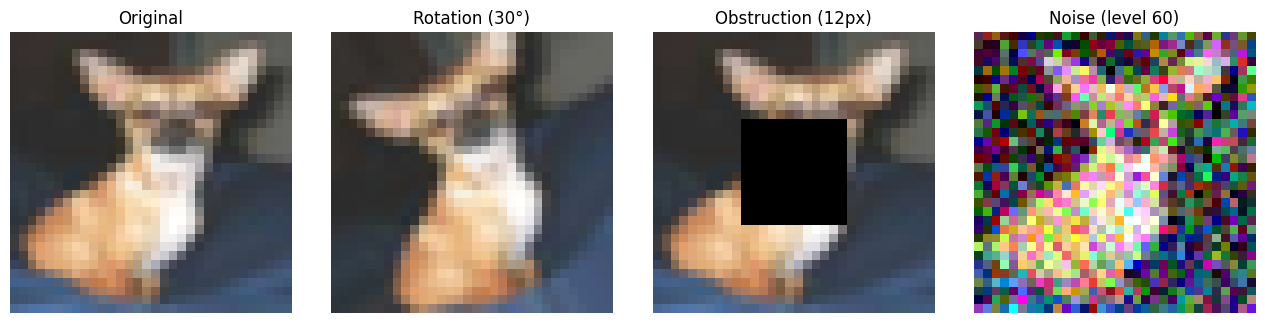

In [ ]:
#@title Run this for a preview of all three transformations { display-mode: "form" }
import numpy as np
from scipy.ndimage import rotate

preview_idx = 220
original_2d = X_test[preview_idx].reshape(32, 32, 3).astype(float)

# Rotation: scipy's rotate, clipped to valid pixel range
rotated = np.clip(rotate(original_2d, 30, reshape=False, mode='nearest'), 0, 255)

# Obstruction: drop a 12x12 black square in the center
blocked = original_2d.copy()
h = w = 32
block_size = 12
y0 = h // 2 - block_size // 2
x0 = w // 2 - block_size // 2
blocked[y0:y0+block_size, x0:x0+block_size] = 0

# Noise: add gaussian noise, clipped to valid pixel range
np.random.seed(42)
noisy = np.clip(original_2d + np.random.normal(0, 60, original_2d.shape), 0, 255)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, img, title in zip(
    axes,
    [original_2d, rotated, blocked, noisy],
    ['Original', 'Rotation (30°)', 'Obstruction (12px)', 'Noise (level 60)'],
):
    ax.imshow(img.astype(int))
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()


## 5.1. Rotating Images

A self-driving car camera might be tilted a few degrees. Does that confuse the CNN?

Below, the same image is rotated through five different angles. Above each rotated image you'll see the CNN's predictioon and how confident it was.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


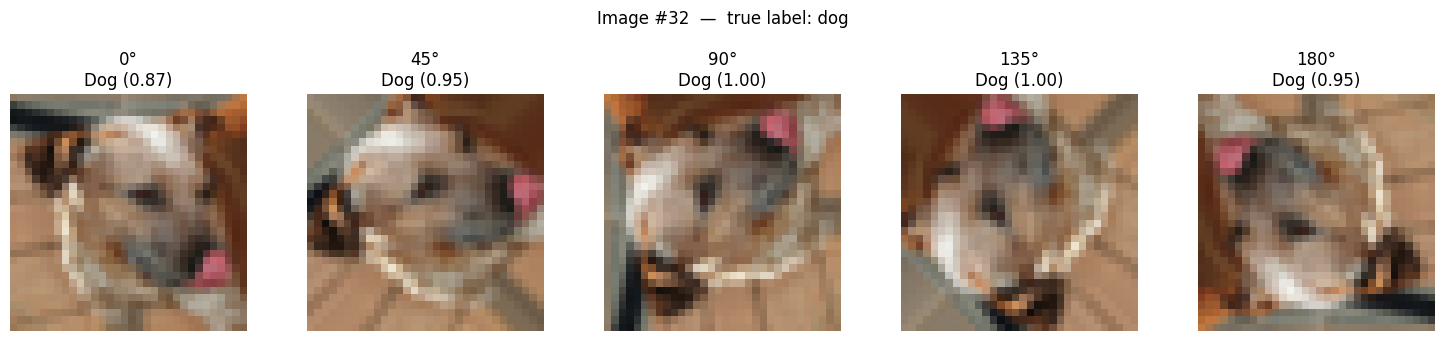

In [ ]:
#@title 5.1 Rotation example { display-mode: "form" }

# Comparison grid — same image rotated at five angles
from scipy.ndimage import rotate

image_index = 32
original_2d = X_test[image_index].reshape(32, 32, 3)

angles = [0, 45, 90, 135, 180]
fig, axes = plt.subplots(1, len(angles), figsize=(15, 3.2))

for ax, a in zip(axes, angles):
    img = np.clip(rotate(original_2d, a, reshape=False, mode='nearest'), 0, 255)
    prob = cnn.predict_proba(np.array([img.flatten()]))[0][0]
    guess = "Dog" if prob > 0.5 else "Road"
    ax.imshow(img.astype(int))
    ax.set_title(f"{a}°\n{guess} ({prob:.2f})")
    ax.axis("off")

plt.suptitle(f"Image #{image_index}  —  true label: {y_test[image_index]}", y=1.05)
plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step


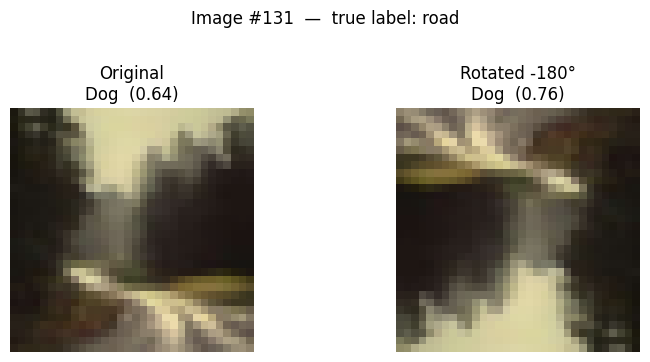

In [ ]:
#@title 5.1 Rotation Playground { run: "auto", display-mode: "form" }
#@markdown **Can you break the model?** Find an image and angle where the CNN is confidently *wrong*.
image_index = 131  #@param {type:"slider", min:0, max:239, step:1}
angle       = -180    #@param {type:"slider", min:-180, max:180, step:5}

original = X_test[image_index].reshape(32, 32, 3)
rotated  = np.clip(rotate(original, angle, reshape=False, mode='nearest'), 0, 255)

orig_prob = cnn.predict_proba(np.array([original.flatten()]))[0][0]
rot_prob  = cnn.predict_proba(np.array([rotated.flatten()]))[0][0]

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].imshow(original.astype(int))
axes[0].set_title(f"Original\n{'Dog' if orig_prob > 0.5 else 'Road'}  ({orig_prob:.2f})")
axes[0].axis("off")
axes[1].imshow(rotated.astype(int))
axes[1].set_title(f"Rotated {angle}°\n{'Dog' if rot_prob > 0.5 else 'Road'}  ({rot_prob:.2f})")
axes[1].axis("off")
plt.suptitle(f"Image #{image_index}  —  true label: {y_test[image_index]}", y=1.02)
plt.tight_layout()
plt.show()


## 5.2. Obstructing Images

Dogs get covered by fences. Cars block parts of the road. Can the CNN handle a little of the picture being missing?

The grid below covers the same image with a 12×12 black square in five different positions. Does the CNN care more about the center or the edges?

> Stop and think: where did the saliency map (Milestone 4) say the CNN was "looking"? Does that match what you see here?


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


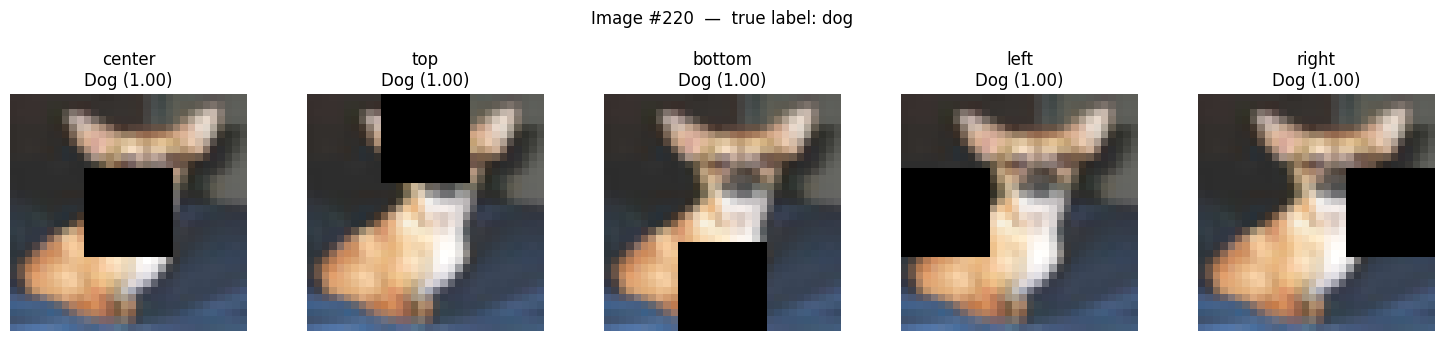

In [ ]:
#@title 5.2 Obstruction example { display-mode: "form" }


# Comparison grid — same image, block in five positions
def block_image(img_2d, position="center", block_size=12):
    h = w = 32
    positions = {
        "center": (h//2 - block_size//2, w//2 - block_size//2),
        "top":    (0,                    w//2 - block_size//2),
        "bottom": (h - block_size,       w//2 - block_size//2),
        "left":   (h//2 - block_size//2, 0),
        "right":  (h//2 - block_size//2, w - block_size),
    }
    y, x = positions[position]
    out = img_2d.copy()
    out[y:y+block_size, x:x+block_size] = 0
    return out

image_index = 220
original_2d = X_test[image_index].reshape(32, 32, 3)

positions = ["center", "top", "bottom", "left", "right"]
fig, axes = plt.subplots(1, len(positions), figsize=(15, 3.2))

for ax, pos in zip(axes, positions):
    img  = block_image(original_2d, pos, 12)
    prob = cnn.predict_proba(np.array([img.flatten()]))[0][0]
    guess = "Dog" if prob > 0.5 else "Road"
    ax.imshow(img.astype(int))
    ax.set_title(f"{pos}\n{guess} ({prob:.2f})")
    ax.axis("off")

plt.suptitle(f"Image #{image_index}  —  true label: {y_test[image_index]}", y=1.05)
plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


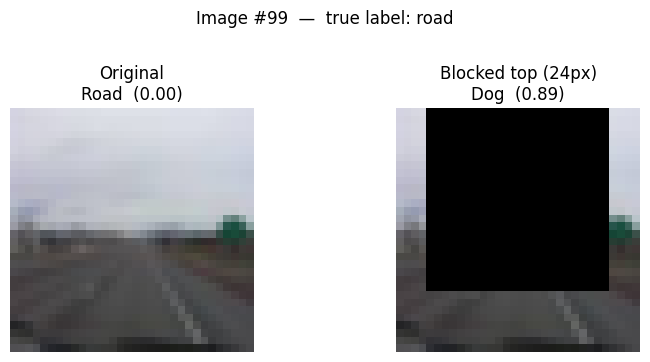

In [ ]:
#@title 5.2 Obstruction Playground { run: "auto", display-mode: "form" }
#@markdown **Can you break the model here?** Find a block position + size that breaks the CNN.
image_index = 99     #@param {type:"slider", min:0, max:239, step:1}
block_size  = 24      #@param {type:"slider", min:0, max:24, step:2}
position    = "top" #@param ["center", "top", "bottom", "left", "right"]

original = X_test[image_index].reshape(32, 32, 3)
blocked  = block_image(original, position, block_size) if block_size > 0 else original.copy()

orig_prob = cnn.predict_proba(np.array([original.flatten()]))[0][0]
blk_prob  = cnn.predict_proba(np.array([blocked.flatten()]))[0][0]

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].imshow(original.astype(int))
axes[0].set_title(f"Original\n{'Dog' if orig_prob > 0.5 else 'Road'}  ({orig_prob:.2f})")
axes[0].axis("off")
axes[1].imshow(blocked.astype(int))
axes[1].set_title(f"Blocked {position} ({block_size}px)\n{'Dog' if blk_prob > 0.5 else 'Road'}  ({blk_prob:.2f})")
axes[1].axis("off")
plt.suptitle(f"Image #{image_index}  —  true label: {y_test[image_index]}", y=1.02)
plt.tight_layout()
plt.show()


## 5.3. Adding Noise

A camera in low light produces grainy images. We simulate that by adding random numbers to every pixel.

The grid below shows the same image at five increasing noise levels.

> Note: we set `np.random.seed(42)` so that you get the *same* noisy images every time you re-run these cells. Without the seed, every run would look a little different.


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 516ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


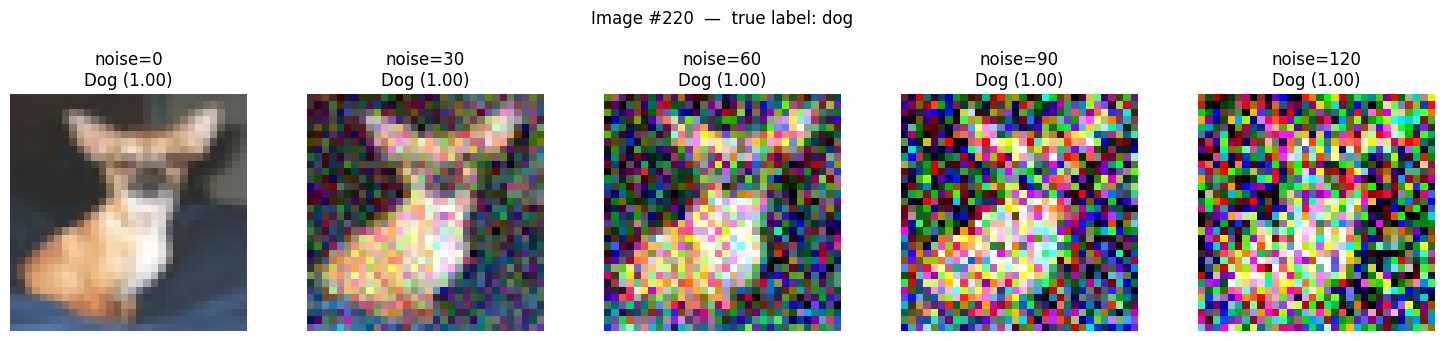

In [ ]:
#@title 5.3 Noise example { display-mode: "form" }

# Comparison grid — same image at five noise levels
np.random.seed(42)

image_index = 220
original_2d = X_test[image_index].reshape(32, 32, 3).astype(float)

levels = [0, 30, 60, 90, 120]
fig, axes = plt.subplots(1, len(levels), figsize=(15, 3.2))

for ax, lvl in zip(axes, levels):
    noise = np.random.normal(0, lvl, original_2d.shape) if lvl > 0 else 0
    noisy = np.clip(original_2d + noise, 0, 255).astype(int)
    prob  = cnn.predict_proba(np.array([noisy.flatten()]))[0][0]
    guess = "Dog" if prob > 0.5 else "Road"
    ax.imshow(noisy)
    ax.set_title(f"noise={lvl}\n{guess} ({prob:.2f})")
    ax.axis("off")

plt.suptitle(f"Image #{image_index}  —  true label: {y_test[image_index]}", y=1.05)
plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step


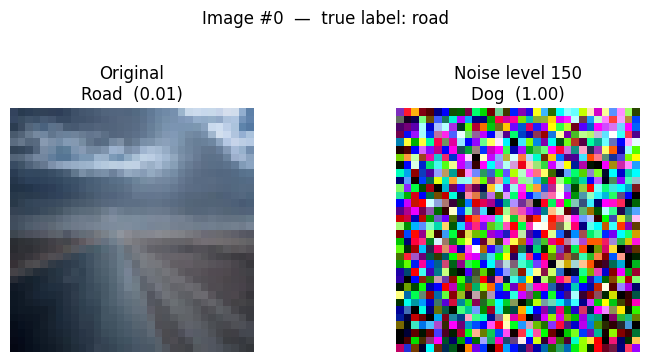

In [ ]:
#@title 5.3 Noise Playground { run: "auto", display-mode: "form" }
#@markdown **What about this one?** Find the noise level where the CNN stops getting it right.
image_index = 0  #@param {type:"slider", min:0, max:239, step:1}
noise_level = 150    #@param {type:"slider", min:0, max:150, step:5}

np.random.seed(42)   # reproducible noise every drag
original = X_test[image_index].reshape(32, 32, 3).astype(float)
noise    = np.random.normal(0, noise_level, original.shape) if noise_level > 0 else 0
noisy    = np.clip(original + noise, 0, 255).astype(int)

orig_prob = cnn.predict_proba(np.array([original.flatten()]))[0][0]
noi_prob  = cnn.predict_proba(np.array([noisy.flatten()]))[0][0]

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].imshow(original.astype(int))
axes[0].set_title(f"Original\n{'Dog' if orig_prob > 0.5 else 'Road'}  ({orig_prob:.2f})")
axes[0].axis("off")
axes[1].imshow(noisy)
axes[1].set_title(f"Noise level {noise_level}\n{'Dog' if noi_prob > 0.5 else 'Road'}  ({noi_prob:.2f})")
axes[1].axis("off")
plt.suptitle(f"Image #{image_index}  —  true label: {y_test[image_index]}", y=1.02)
plt.tight_layout()
plt.show()


## 5.4. Discussion Exercise


In [ ]:
#@markdown *1. Out of rotation, obstruction, and noise — at what point did your model start failing? Is this acceptable for a self-driving car?*
answer_1 = "" # @param {"type":"string"}

#@markdown *2. Out of rotation, obstruction, and noise — which one breaks the model most easily? Why do you think that is?*
breaks_most = "(pick one)" #@param ["(pick one)", "Rotation", "Obstruction", "Noise"]

check_dropdown_answer(
    breaks_most,
    correct="Rotation",
    feedback_correct="Right — our training set only contains upright images, so the CNN has literally never seen a rotated dog. It has no idea what to look for.",
    feedback_incorrect="Think about which transformation the model has never seen during training. It can't generalise to something it's never encountered."
)

#@markdown *3. What could we do to make the CNN more robust to all three of these problems?*
answer_3 = "" # @param {"type":"string"}

handle_discussion_response(answer_1, answer_3)

## <font color="#4a6fa5"><b>(Optional)</b> Stress Test Playground</font>

> *Finished early? Try stacking all three attacks at once.*

Real-world conditions rarely come one at a time. Drag all four sliders to rotate, block, and add noise to the same image simultaneously, and see how much the CNN can take.

In [ ]:
#@title Combined Stress Test { run: "auto", display-mode: "form" }
#@markdown **Model's worst nightmare:** Combines rotation + obstruction + noise on the same image.
image_index = 0  #@param {type:"slider", min:0, max:239, step:1}
angle       = 0    #@param {type:"slider", min:-180, max:180, step:5}
block_size  = 0    #@param {type:"slider", min:0, max:24, step:2}
noise_level = 0    #@param {type:"slider", min:0, max:150, step:5}

np.random.seed(42)
original = X_test[image_index].reshape(32, 32, 3).astype(float)

# 1. rotate
step = rotate(original, angle, reshape=False, mode='nearest')
# 2. block center
if block_size > 0:
    y = x = 16 - block_size // 2
    step[y:y+block_size, x:x+block_size] = 0
# 3. noise
if noise_level > 0:
    step = step + np.random.normal(0, noise_level, step.shape)

combo = np.clip(step, 0, 255).astype(int)

orig_prob = cnn.predict_proba(np.array([original.flatten()]))[0][0]
combo_prob = cnn.predict_proba(np.array([combo.flatten()]))[0][0]

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].imshow(original.astype(int))
axes[0].set_title(f"Original\n{'Dog' if orig_prob > 0.5 else 'Road'}  ({orig_prob:.2f})")
axes[0].axis("off")
axes[1].imshow(combo)
axes[1].set_title(f"Rot {angle}° + Block {block_size}px + Noise {noise_level}\n{'Dog' if combo_prob > 0.5 else 'Road'}  ({combo_prob:.2f})")
axes[1].axis("off")
plt.suptitle(f"Image #{image_index}  —  true label: {y_test[image_index]}", y=1.02)
plt.tight_layout()
plt.show()


✅ **Milestone 5 done!** You've stress-tested the model and seen its limits. Now the fun part — take everything you've learned and turn it into a real deployed app.

<!-- ⏱ Suggested time: 10–15 min depending on group pace -->
---
---
# **🚀 (Optional) Milestone 6: Vibe Code Your Own CV App**

Now that you've seen how a model learns to see (and how to interpret what it focuses on), it's time to build something of your own!


> The most important skill in AI isn't coding — it's finding meaningful problems and designing effective solutions. In this milestone you'll brainstorm **your own CV app idea**, generate it with AI, and deploy it live!

<img src="https://us.v-cdn.net/6036147/uploads/QR9F7ZY5FDWO/lovable-for-vibe-coding.jpg" width="700">

Next, we'll brainstorm CV app ideas together — then you'll design and build your own from scratch with Lovable and deploy it live.

## 6.1. What Can CV Apps Do?

<left>
<img src="https://serokell.io/files/1c/1c5lire1.Deep_Learning_in_Computer_Vision_pic4.png" width=750>
</left>

Computer vision apps can tackle all kinds of real-world problems:

- **Nature:** identify plant species from a photo, track wildlife from camera traps, detect wildfires from satellite images
- **Health:** spot early signs of skin conditions, count cells in a microscope image, flag unusual X-rays for review
- **Safety:** detect if a driver looks drowsy, check if workers are wearing PPE, read road signs in real time
- **Fun:** turn your photo into a painting style, gesture-controlled game, apply face filters in real time

### 🌐 3 directions to pick your app

- 🎯 **Close to today's notebook** — an app that builds directly on what we did today.
  *(e.g. "extending the dog-vs-road classifier into an app, with a saliency map to explain its decisions")*
- 🔀 **Same technique, different topic** — the same approach applied to a totally different problem.
  *(e.g. "classify plant diseases")*
- 🪄 **Anything you want** — any app idea, even unrelated to today's content.
  *(e.g. "turn my doodles into emoji" — go wild)*

Pick whichever direction speaks to you, then sketch your app below.

In [ ]:
#@title 💭 6.1 — Brainstorm: design your app  {"display-mode":"form", "form-width":"25%"}

#@markdown **🎯 What does the app do?**
#@markdown *(💭 To brainstorm: what problem does it help solve? Then describe what the app does in plain language — e.g. "Identifies plant species from a photo so hikers know what's safe to touch")*
APP_GOAL = ""  # @param {"type":"string"}

#@markdown **👥 Who is the user?**
#@markdown *(e.g. "Hikers and outdoor enthusiasts")*
APP_USER = ""  # @param {"type":"string"}

#@markdown **📸 What does the user show or upload?**
#@markdown *(e.g. "A photo of a plant or leaf")*
USER_INPUT = ""  # @param {"type":"string"}

#@markdown **💡 What does the app give back?**
#@markdown *(e.g. "Plant name, safety rating, and a short description")*
APP_OUTPUT = ""  # @param {"type":"string"}

#@markdown **🏷️ App name**
#@markdown *(e.g. "PlantSafe — Know Before You Touch" or "WildlifeSpotter")*
APP_NAME = ""  # @param {"type":"string"}

#@markdown **🎨 Visual style / theme**
#@markdown *(e.g. "clean and minimal", "fun and colorful", "dark and futuristic")*
APP_THEME = ""  # @param {"type":"string"}

#@markdown **🌟 Extra features (optional)**
#@markdown *(e.g. "a map showing where the plant grows" or "a share button")*
EXTRA = ""  # @param {"type":"string"}

assert all(v.strip() for v in [APP_GOAL, APP_USER, USER_INPUT, APP_OUTPUT, APP_NAME, APP_THEME]), \
    "Fill in all required fields above before continuing (EXTRA is optional)."

print(f"✅ Design saved for: {APP_NAME}")


## 6.2. Generate Your Lovable Prompt

Now generate a Lovable prompt from your design — copy it from the cell below, then paste it into Lovable in 6.3.

In [ ]:
#@title 🚀 6.2 — Generate your Lovable prompt (run this cell, then copy it!) { display-mode: "form" }

from IPython.display import display, Javascript, HTML

prompt = f"""Build a web app called "{APP_NAME}".

What it does: {APP_GOAL}
Who it's for: {APP_USER}

The user uploads or shows: {USER_INPUT}. The app gives back: {APP_OUTPUT}.
Visual style: {APP_THEME}.
{f"Extra features: {EXTRA}" if EXTRA.strip() else ""}

Requirements:
- Clean, polished UI with the app name as the title and a one-line description
- A clear upload or input area for the user
- A results section that shows the output in a visually appealing way
- 2-3 example inputs the user can click to try (use realistic placeholder data)
- Handle errors gracefully (e.g. wrong file type, nothing uploaded yet)
- Keep it simple and focused — one main feature done really well"""

# Store prompt in a JS variable to avoid escaping issues in onclick
display(HTML(f"""
<div style="font-family:sans-serif; max-width:620px; margin-top:12px;">
    <div id="prompt-box" style="
        background:#f8f9fa;
        border:1px solid #ddd;
        border-radius:8px;
        padding:16px 20px;
        white-space:pre-wrap;
        font-size:13px;
        line-height:1.6;
        color:#1a1a1a;
        margin-bottom:12px;
    ">{prompt}</div>
    <button id="copy-btn" style="
        background:#4A90D9;
        color:white;
        border:none;
        border-radius:6px;
        padding:10px 20px;
        font-size:14px;
        cursor:pointer;
    ">Copy prompt</button>
</div>
<script>
    document.getElementById('copy-btn').addEventListener('click', function() {{
        var text = document.getElementById('prompt-box').innerText;
        navigator.clipboard.writeText(text).then(function() {{
            document.getElementById('copy-btn').textContent = '✅ Copied!';
            setTimeout(function() {{
                document.getElementById('copy-btn').textContent = 'Copy prompt';
            }}, 2000);
        }});
    }});
</script>
"""))

Note: Today you're building a **polished prototype**, but Lovable can call vision APIs (e.g. Google Vision, OpenAI) directly — so your app can do real image classification without hosting a model yourself. If you want to deploy your *own* trained CNN, you'd host it on HuggingFace Spaces and connect it via an API. That comes later.

## 6.3. Deploy on Lovable 🚀

Now enter your prompt on [**Lovable**](https://lovable.dev) to start building and improving your app!

📧 Your instructor will add you to class workspace so you have paid credits ready to go.

**Steps:**
1. Check your email for a Lovable workspace invitation and click **"Join workspace"**
2. Go to [**lovable.dev**](https://lovable.dev) and sign in with the email your instructor invited
3. Paste your prompt in the main text box — Lovable will begin building your app!
4. Test it, iterate, and improve — describe any changes you want
5. Click **"Publish"** to get a live link you can share with anyone!

> 💡 **Tip:** Not happy with something? Just tell Lovable what to fix in plain English. That's vibe coding!


### Tips for Vibe Coding

Describe what you want in plain English — be specific about what you see and what you want instead.

**Try these upgrades:**

| What you want | What to type |
|---|---|
| Change the look | *"Make it dark mode with neon green accents"* |
| Better results display | *"Show the result as a progress bar instead of plain text"* |
| Example gallery | *"Add a grid of 6 example images the user can click to test"* |
| Add context | *"Add a short 'How it works' section explaining the AI behind this"* |
| Mobile-friendly | *"Make the upload button bigger and easier to tap on a phone"* |
| Share button | *"Add a button that copies the result to the clipboard"* |

**When things go wrong:**

- **Something's broken** — describe exactly what you see and what you expected: *"The upload button disappears after I select a file — it should stay visible"*
- **Want something new** — lead with the outcome: *"I want users to compare two images side by side"*
- **Feeling stuck** — ask Lovable to explain itself: *"Walk me through how this app works"*

> The skill here isn't knowing how to code — it's knowing what you want and describing it clearly. That's what makes a great product designer or AI engineer.

In [ ]:
#@title Before you wrap up — check your app! { display-mode: "form" }
import ipywidgets as widgets
from IPython.display import display

items = [
    ("Planned", "you filled in a real problem, user, and CV use case"),
    ("Upgraded", "you made at least one improvement via the Lovable chat"),
    ("Polished", "clean design, clear description, example inputs work"),
    ("Deployed", "you have a live Lovable link you can share"),
]

congrats = widgets.HTML(value="", layout=widgets.Layout(margin='12px 0 0 0'))
checkboxes = []

def check_all(_):
    if all(cb.value for cb in checkboxes):
        congrats.value = '''<div style="
            font-size:16px; font-weight:600; color:#2e7d32;
            background:#e8f5e9; border-radius:8px;
            padding:12px 16px; margin-top:8px;">
            🚀 Congrats! You built and deployed a real AI app. That's the start of your AI portfolio.
        </div>'''
    else:
        congrats.value = ""

rows = []
for bold, desc in items:
    cb = widgets.Checkbox(value=False, indent=False, layout=widgets.Layout(width='20px'))
    cb.observe(check_all, names='value')
    checkboxes.append(cb)
    label = widgets.HTML(f'<span style="font-size:15px;"><b>{bold}</b> — {desc}</span>')
    rows.append(widgets.HBox([cb, label], layout=widgets.Layout(align_items='center', margin='4px 0')))

display(*rows, congrats)

## <font color="#4a6fa5"><b>(Optional)</b> ⭐ Bonus App Ideas!</font>

> *More time? Try these stretch challenges!*

**Challenge:** Push your app further! Pick one of these to try:

- **Add a confidence display:** Ask Lovable to show how confident the AI is in its answer (e.g. "87% sure this is a daisy")
- **Add a "How does CV work?" explainer:** Ask Lovable to add a collapsible section explaining how computer vision works in plain English
- **Compare two inputs:** Ask Lovable to let users upload two images and compare the results side by side
- **Brand it:** Give your app a logo, a tagline, and a color scheme that matches your theme


---
---
# ✍️ Reflection Questions

In [ ]:
#@title {"display-mode":"form", "form-width":"25%"}
#@markdown **🏗 Builder Question:** What would add to the dog vs. road classifier to make it more useful?
builder_answer = "" # @param {"type":"string"}

#@markdown **⚖️ Ethics Question:** Our model was only trained on dogs and roads. What could go wrong if it encounters something it hasn't seen (a cat, a person, a bicycle)?
ethics_answer = "" # @param {"type":"string"}

handle_discussion_response(builder_answer, ethics_answer)

<!-- ⏱ Suggested time: 10–15 min depending on group pace -->
---
---
# <font color="#4a6fa5"><b>(Optional)</b> **🌐 Milestone 7: Frontier AI & Multimodal Models**</font>

> Our CNN was trained to classify dogs vs. roads — just two categories. But modern AI models like GPT-5, Claude, and Gemini can understand *any* image and describe it in natural language. How? Let's find out!

<img src="https://media2.dev.to/dynamic/image/width=800%2Cheight=%2Cfit=scale-down%2Cgravity=auto%2Cformat=auto/https%3A%2F%2Fdev-to-uploads.s3.amazonaws.com%2Fuploads%2Farticles%2Fc5pg9xvutj62us9r4giu.png" width="700">

## <font color="#4a6fa5"><b>(Optional)</b> 7.1. From Categories to Understanding</font>

> Try this section if you want to see how frontier models compare to our CNN.

Our CNN was trained on labeled images: each image was tagged as "dog" or "road." **Frontier models** like GPT-4o, Claude, and Gemini were trained on millions of text-image pairs instead — so they learn *what things look like and how to talk about them*, not just two specific categories.

| | Our CNN | Frontier Models (GPT-4o, Claude, etc.) |
|---|---|---|
| **Training data** | Images labeled "dog" or "road" | Millions of text-image pairs |
| **What it learns** | Patterns for 2 specific categories | General visual understanding |
| **Output** | "dog" or "road" | Natural language description |
| **New categories?** | ❌ Can't handle anything else | ✅ Can describe anything |

## <font color="#4a6fa5"><b>(Optional)</b> 7.2. Seeing What Frontier AI Sees</font>

> Try this section if you want to send one of our dataset images to GPT-4o-mini and see how it responds — using the same OpenAI API as in the previous notebook.

In [ ]:
!pip install openai -q

Now, paste your shared API key to access their AI models from this notebook. (Ask your instructor for the shared API key).

In [ ]:
#@title Paste your API key here {"display-mode":"form", "form-width":"25%"}
API_KEY = ""  # @param {type:"string"}
API_KEY = API_KEY.strip()

if not API_KEY:
    print("⚠️ Paste your OpenAI key above, then re-run this cell.")
elif not API_KEY.startswith("sk-"):
    print("⚠️ That doesn't look like an OpenAI key — it should start with 'sk-'. Try again.")
else:
    print("✅ OpenAI API key loaded")

Now create the OpenAI client connection:

In [ ]:
from openai import OpenAI
import base64

# Create the client
client = OpenAI(api_key=API_KEY) # Uses the API key you pasted above
print("✅ Connected to OpenAI!" if API_KEY else "⚠️ Paste your API key above first!")

To test, pick an image from our initial dataset.

In [ ]:
#@title Pick a test image — move the slider! { display-mode: "form" }
image_index = 50 #@param {type:"slider", min:0, max:199, step:1}

input_image = X_test[image_index]
true_label = y_test[image_index]

plt.imshow(input_image.reshape(32, 32, 3).astype(int))
plt.title(f"Image {image_index} — True label: {true_label}")
plt.axis('off')
plt.show()

Now let's send the image to GPT-4o-mini and ask it what it sees:

In [ ]:
import base64
from io import BytesIO
from PIL import Image

## Add your question, about the chosen image below (e.g. ask it to describe the image)
question = input("What's your question? ")

# This function converts our image into a format the API can understand.
# APIs can't accept raw numpy arrays, so we convert it to a base64 string —
# a way of representing any file (like an image) as plain text.
def image_to_base64(image_array):
    # Reshape the flat pixel list back into a 32x32 colour image
    img = Image.fromarray(image_array.reshape(32, 32, 3).astype('uint8'))

    # Scale up to 256x256 so the AI can see it more clearly
    # NEAREST keeps the blocky pixel look instead of blurring it
    img = img.resize((256, 256), Image.NEAREST)

    # Save the image into memory as a PNG (not to disk)
    buffer = BytesIO()
    img.save(buffer, format="PNG")

    # Return the image as a base64 string — the format the API expects
    return base64.b64encode(buffer.getvalue()).decode('utf-8')


# Pick an image from our test set and display it
image_index = 220  # Try changing this to any number between 0 and 239
test_image  = X_test[image_index]
true_label  = y_test[image_index]

plt.imshow(test_image.reshape(32, 32, 3).astype(int))
plt.title(f"True label: {true_label}")
plt.show()

# Convert the image to base64 so we can send it to the API
img_b64 = image_to_base64(test_image)

# Send the image to GPT-4o-mini with a question
# The API takes a list of messages — here we send one message with
# both a text prompt and the image attached
response = client.chat.completions.create(
    model="gpt-4o-mini",
    # Adds your question as the text
    messages=[
        {"role": "user", "content": [
            {"type": "text",
             "text": question},
            {"type": "image_url",
             "image_url": {"url": f"data:image/png;base64,{img_b64}"}}
        ]}
    ]
)

# Print what GPT-4o-mini said
print("🤖 GPT-4o-mini says:")
print(response.choices[0].message.content)

Notice the difference: our CNN just says "dog" or "road." GPT-4o-mini can **describe** what it sees, explain its reasoning, and handle images it's never been specifically trained on.

### <font color="#4a6fa5"><b>(Optional)</b> 7.2.1. Compare to the Frontier Model
</font>

Now let's run a loop sending the first 5 misclassified images to GPT-4o-mini and see how it does.

> Run the cell below — it'll print the original image, what the CNN predicted (wrongly), and what GPT-4o-mini says.

In [ ]:
# Find all images the CNN got wrong

# Predict all test images at once
all_predictions = cnn.predict(X_test)

# Convert one-hot predictions ([1,0] or [0,1]) to string labels to match y_test
predicted_labels = ["dog" if pred[0] == 1 else "road" for pred in all_predictions]

# Find every index where the prediction doesn't match the true label
wrong_indices = [idx for idx, (pred, true) in enumerate(zip(predicted_labels, y_test)) if pred != true]

print(f"CNN got {len(wrong_indices)} out of {len(X_test)} images wrong")
print(f"Wrong indices: {wrong_indices}")

In [ ]:
#@title Run cell to compare CNN mistakes against GPT-4o-mini  {"display-mode":"form", "form-width":"25%"}

# Look at the first 5 images the CNN got wrong and ask GPT-4o-mini about each one
for idx in wrong_indices[:5]:
    test_img   = X_test[idx]
    true_label = y_test[idx]

    # Get the CNN's prediction and confidence for this image
    cnn_pred  = cnn.predict_proba(np.array([test_img]))
    cnn_label = "dog" if cnn_pred[0][0] > 0.5 else "road"
    confidence = max(cnn_pred[0][0], cnn_pred[0][1])

    # Show the image with the CNN's (wrong) prediction
    plt.imshow(test_img.reshape(32, 32, 3).astype(int))
    plt.title(f"True: {true_label}  |  CNN said: {cnn_label}  ({confidence:.0%} confident)")
    plt.axis('off')
    plt.show()

    # Ask GPT-4o-mini the same question — does it get it right?
    img_b64  = image_to_base64(test_img)
    response = client.chat.completions.create(
        model="gpt-4o-mini",
        messages=[
            {"role": "user", "content": [
                {"type": "text",
                 "text": "What is in this image? Is it a dog or a road? Answer in one sentence."},
                {"type": "image_url",
                 "image_url": {"url": f"data:image/png;base64,{img_b64}"}}
            ]}
        ]
    )

    print(f"GPT-4o-mini: {response.choices[0].message.content}")
    print()


## <font color="#4a6fa5"><b>(Optional)</b> 7.3. Stress Testing the Frontier Model</font>

> *Finished early or curious? This section pushes GPT-4o-mini the same way we pushed the CNN in Milestone 5.*

Remember how rotation and noise broke our CNN? Let's run the same attacks on `gpt-4o-mini` and see if it holds up. This section uses a slider playground so you can try different distortions.

In [ ]:
#@title Run to define `ask_gpt` function to send any image to the GPT model


# A reusable helper function for sending any image to GPT-4o-mini (for the stress test below)
def ask_gpt(image, question, model="gpt-4o-mini"):

    # Convert the image to base64 so the API can read it (defined in section 7.2)
    img_b64 = image_to_base64(image)

    # Send the image and question to the model
    response = client.chat.completions.create(
        model=model,
        messages=[{
            "role": "user",
            "content": [
                {"type": "text",      "text": question},
                {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{img_b64}"}},
            ],
        }],
    )

    # Extract and return just the text of the model's reply
    return response.choices[0].message.content



Because each run hits the OpenAI API, the cell **does not** auto-update. Drag the sliders to pick your settings, then hit ▶ to run.

You can also try editing the prompt for further testing - e.g. what happens if you ask the model to rate it's own confidence?


In [ ]:
#@title Frontier Stress Test — drag sliders, then press ▶ { display-mode: "form" }
#@markdown Runs the SAME distorted image through both the CNN and GPT-4o-mini so you can compare.
#@markdown
#@markdown > ⚠️ This cell calls the OpenAI API every time you run it. Pick your settings with the sliders first, then press play.

image_index = 220  #@param {type:"slider", min:0, max:239, step:1}
angle       = 0    #@param {type:"slider", min:-180, max:180, step:5}
noise_level = 0    #@param {type:"slider", min:0, max:150, step:5}
prompt      = "Is this image a dog or a road? Answer in one sentence." #@param {type:"string"}

np.random.seed(42)
img_2d = X_test[image_index].reshape(32, 32, 3).astype(float)

# Apply rotation + noise
rot       = rotate(img_2d, angle, reshape=False, mode='nearest')
distorted = np.clip(rot + np.random.normal(0, noise_level, rot.shape) if noise_level > 0 else rot,
                    0, 255).astype(int)

# Show the distorted image
plt.figure(figsize=(4, 4))
plt.imshow(distorted)
plt.title(f"Image #{image_index}  |  Rotated {angle}°  |  Noise {noise_level}")
plt.axis("off")
plt.show()

# CNN prediction
cnn_prob  = cnn.predict_proba(np.array([distorted.flatten()]))[0][0]
cnn_label = "Dog" if cnn_prob > 0.5 else "Road"
print(f"True label: {y_test[image_index]}")
print(f"CNN says: {cnn_label}  (dog probability: {cnn_prob:.3f})")
print()

# GPT prediction
print("Asking GPT-4o-mini…")
gpt_answer = ask_gpt(distorted.flatten(), prompt)
print(f"GPT-4o-mini says: {gpt_answer}")


### <font color="#4a6fa5"><b>(Optional)</b> 7.3.1. Discussion Exercise</font>


In [ ]:
#@markdown *1. How did GPT-4o-mini handle the distorted images compared to our CNN?*
answer_1 = "" # @param {"type":"string"}

#@markdown *2. Why might a model trained on text-image pairs be more robust than one trained on just two categories?*
answer_2 = "" # @param {"type":"string"}

handle_discussion_response(answer_1, answer_2)


---
---

# 🤔 Knowledge Check

Great job completing this notebook! Answer these questions to lock in what you've learned.

In [ ]:
#@markdown *1. In this notebook, you implemented an example of computer vision! What is computer vision?*
answer_1 = "" # @param {"type":"string"}

#@markdown *2. What is a saliency map, and why is it useful?*
answer_2 = "" # @param {"type":"string"}

#@markdown *3. Why did our CNN struggle with rotated images?*
answer_3 = "" # @param {"type":"string"}


#@markdown *4. What does "vibe coding" mean?*
answer_4 = "" # @param {"type":"string"}

handle_discussion_response(answer_1, answer_2, answer_3, answer_4)

---
---

# 📋 Resources

Feel free to use the following as quick references:

- [Scikit-learn Pipeline Cheat Sheet](https://docs.google.com/document/d/1NK3wvy9pnpg6vab6AkdzLwGSsNf31NSIsrEYz1IVljk/edit?tab=t.53r5m2rr4htd)
- [Scikit-learn Models Cheat Sheet](https://docs.google.com/document/d/1NK3wvy9pnpg6vab6AkdzLwGSsNf31NSIsrEYz1IVljk/edit?pli=1&tab=t.ievqibqbhol1)
- [CNN Explainer](https://poloclub.github.io/cnn-explainer/) — interactive visualization of how CNNs see images
- [OpenAI API Docs](https://platform.openai.com/docs/quickstart)
- [Lovable Docs](https://docs.lovable.dev)

🚀 **You've gone from training a model → understanding what it sees → stress testing it → deploying a live app. That's real AI engineering!**


---
### 🔜 Next Session: NLP & Large Language Models — You'll explore how AI understands language, from word embeddings to LLMs, and build your own NLP-powered app!